AI has been used for debugging and problems with code 

In [53]:
import pandas as pd
import numpy as np
import matplotlib as plt
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import classification_report, confusion_matrix
from matplotlib.pyplot import figure

IMporting libraries

In [54]:
path = r"C:\Users\rzepa\Desktop\IoT MLs\cleaned_dataset.csv"
df = pd.read_csv(path)

reading the cleaned dataset csv file

In [55]:
print(df.shape)

(447210, 9)


In [56]:
print(df["recording"].value_counts())

recording
downstairs    170405
upstairs      150547
situps         64130
push ups       62128
Name: count, dtype: int64


printing the recordings for each activity 

In [57]:
sensor_columns = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]
win_size = 300 # 300 samples in data set is 3 seconds at 100hz (which we recorded at)

assigning the 6 sensor axes and reading per window which is 3 seconds at 100Hz which is what the app we used records at

In [58]:
def window_features(box):
    feats = {}
    for col in sensor_columns:
        v = box[col]
        feats[f"{col}_mean"] = v.mean()
        feats[f"{col}_std"] = v.std()
        feats[f"{col}_min"] = v.min()
        feats[f"{col}_max"] = v.max()
        feats[f"{col}_median"] = v.median()
        feats[f"{col}_25%"] = v.quantile(0.25)
        feats[f"{col}_75%"] = v.quantile(0.75)
        
    acc_sec = np.sqrt((box[["acc_x", "acc_y", "acc_z"]] ** 2).sum(axis=1))
    gyro_sec = np.sqrt((box[["gyro_x", "gyro_y", "gyro_z"]] ** 2).sum(axis=1))
    for name,sec in [("acc_sec", acc_sec), ("gyro_sec", gyro_sec)]:
        feats[f"{name}_mean"] = sec.mean()
        feats[f"{name}_std"] = sec.std()
        feats[f"{name}_max"] = sec.max()
    return feats

turning 300 readings into 48 numbers. mean std, min, max, median, 25 and 75th percentile.

In [59]:
rows, labels = [], []
for session, g in df.groupby("activity", sort = False):
    for start in range (0, len(g) - win_size + 1, win_size):
        chunk = g.iloc[start:start + win_size]
        rows.append(window_features(chunk))
        labels.append(g["recording"].iloc[0])

making sure no windows are mixed, no overlapping of 300 readings adn assigning features 

In [60]:
X = pd.DataFrame(rows)
y = np.array(labels)
print(X.shape)
print(pd.Series(y).value_counts())

(1435, 48)
downstairs    556
upstairs      490
situps        200
push ups      189
Name: count, dtype: int64


X is the features table and y is the eky

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, stratify=y, random_state=50)

training at 40% and test at 60%

In [62]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=50)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

  downstairs       0.84      0.93      0.88       222
    push ups       0.99      0.88      0.93        76
      situps       1.00      0.99      0.99        80
    upstairs       0.90      0.84      0.87       196

    accuracy                           0.90       574
   macro avg       0.93      0.91      0.92       574
weighted avg       0.90      0.90      0.90       574



classification report

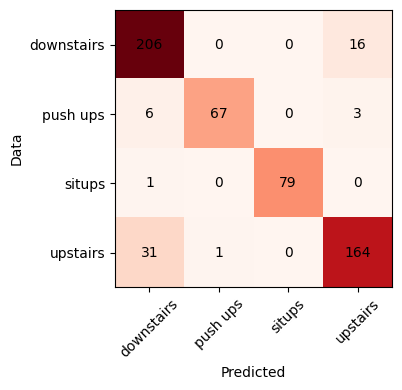

In [63]:
labels_list = sorted(set(y))
cm = confusion_matrix(y_test, pred, labels=labels_list)
figure(figsize=(5, 4))
plt.imshow(cm, cmap="Reds")
plt.xticks(range(len(labels_list)), labels_list, rotation=45)
plt.yticks(range(len(labels_list)), labels_list)
for i in range(len(labels_list)):
    for j in range(len(labels_list)):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("Predicted")
plt.ylabel("Data")
plt.tight_layout()
plt.show()

confusion matrix